# 05 · Completing the analysis
A. Who pays whom: customer numbers, entities and neighbourhoods (new)
B. Anomalies: remaining tests and dashboard charts
C. Path endpoints that differ from the BIC columns
D. Weekend effect in local time
E. Dashboard charts for rules established in notebooks 01–03
Every chart is saved to `outputs/charts/` and its table to `outputs/csv/`.

In [1]:
import sys; sys.path.insert(0, '../src')
from utils import q, rule_check, savefig, export, con
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## A. Customer numbers, entities and neighbourhoods
### H-A1  An IBAN-style account is built as: country (2) + check digits (2) + bank code (4) + … + customer number (last 9 digits); the bank code is the first 4 characters of the BIC

In [2]:
pd.concat([
  rule_check('ordering IBAN: all 28 characters long', 'length(ORDERING_ACCOUNT)=28', 'ORD_ACC_IS_IBAN'),
  rule_check('ordering IBAN chars 5-8 = first 4 of ORDERING_BIC8', 'substr(ORDERING_ACCOUNT,11,4)=substr(ORDERING_BIC8,1,4)', 'ORD_ACC_IS_IBAN'),
  rule_check('beneficiary IBAN chars 5-8 = first 4 of BENEFICIARY_BIC8', 'substr(BENEFICIARY_ACCOUNT,11,4)=substr(BENEFICIARY_BIC8,1,4)', 'BEN_ACC_IS_IBAN'),
  rule_check('ordering IBAN country = bank country', 'ORD_ACC_COUNTRY=ORD_COUNTRY', 'ORD_ACC_IS_IBAN'),
])

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,ordering IBAN: all 28 characters long,5660241,5660241.0,100.0,0.0
0,ordering IBAN chars 5-8 = first 4 of ORDERING_...,5660241,5660241.0,100.0,0.0
0,beneficiary IBAN chars 5-8 = first 4 of BENEFI...,5621388,5621388.0,100.0,0.0
0,ordering IBAN country = bank country,5660241,5660241.0,100.0,0.0


### H-A2  The customer number identifies the party, not the account: one beneficiary holds accounts at several banks, with one name and one address country
Scope: payments where both accounts are IBAN-style (about 30% of rows), because only there can the customer number be read reliably.

In [3]:
con.execute('''CREATE OR REPLACE TEMP TABLE ib AS
  SELECT ROW_ID, right(ORDERING_ACCOUNT,9)::BIGINT oid, right(BENEFICIARY_ACCOUNT,9)::BIGINT bid, ORDERING_ACCOUNT oa, BENEFICIARY_ACCOUNT ba,
         BEN_COUNTRY, BEN_DETAILS_COUNTRY, ANOMALY, FLOW, EPOCH_SECONDS
  FROM f WHERE ORD_ACC_IS_IBAN AND BEN_ACC_IS_IBAN''')
ent = q('''SELECT count(*) payments, count(DISTINCT oa) sender_accounts, count(DISTINCT oid) sender_customer_numbers,
                  count(DISTINCT ba) receiver_accounts, count(DISTINCT bid) receiver_customer_numbers FROM ib'''); export(ent,'entity_counts'); ent.T

,0
payments,3097868
sender_accounts,94549
sender_customer_numbers,94549
receiver_accounts,781150
receiver_customer_numbers,208428


In [4]:
pd.concat([
  rule_check('receiver customer number -> one address country', 'n=1', table="(SELECT count(DISTINCT BEN_DETAILS_COUNTRY) n FROM ib WHERE BEN_DETAILS_COUNTRY IS NOT NULL GROUP BY bid)"),
  rule_check('receiver customer number -> more than one bank country (among those with 5+ payments)', 'n>1', table="(SELECT count(DISTINCT BEN_COUNTRY) n FROM ib GROUP BY bid HAVING count(*)>=5)"),
])

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,receiver customer number -> one address country,163830,163830.0,100.0000,0.0
0,receiver customer number -> more than one bank...,52529,33182.0,63.1689,19347.0


In [5]:
acc = q('''SELECT least(n,8) AS accounts_per_receiver, count(*) receivers FROM (SELECT bid, count(DISTINCT ba) n FROM ib GROUP BY 1) GROUP BY 1 ORDER BY 1''')
acc['share'] = acc.receivers/acc.receivers.sum(); export(acc,'entity_accounts_per_receiver'); acc

,accounts_per_receiver,receivers,share
0,1,137052,0.657551
1,2,28954,0.138916
2,3,12303,0.059028
3,4,7010,0.033633
4,5,4198,0.020141
5,6,2996,0.014374
6,7,2169,0.010406
7,8,13746,0.065951


Senders have one account each (sender accounts = sender customer numbers). Receivers do not: the same person or firm is paid at different banks. This is why the beneficiary *address* country rarely equals the beneficiary *bank* country (P5/P6).

### H-A3  Payment relationships repeat at the level of the party, which the account level hides

In [6]:
rep = q('''SELECT 'account pair' AS level, avg((c>1)::int) AS share_of_pairs_repeating, sum(c) FILTER (c>1)/sum(c) AS share_of_payments_in_repeating_pairs
           FROM (SELECT count(*) c FROM ib WHERE ANOMALY='NONE' GROUP BY oa, ba)
           UNION ALL SELECT 'customer-number pair', avg((c>1)::int), sum(c) FILTER (c>1)/sum(c)
           FROM (SELECT count(*) c FROM ib WHERE ANOMALY='NONE' GROUP BY oid, bid)'''); export(rep,'entity_repeat_relationships'); rep

,level,share_of_pairs_repeating,share_of_payments_in_repeating_pairs
0,account pair,0.123904,0.317039
1,customer-number pair,0.143028,0.443978


### H-A4  Senders prefer receivers whose customer number is close to their own (a 'neighbourhood' in the generator)
Baseline: if receivers were picked without regard to the number, the share within ±1,000 would be about the share of all receiver numbers in that window.

In [7]:
bins = [0,10,100,1000,10000,100000,10**7]; labels = ['<10','10–99','100–999','1k–10k','10k–100k','100k+']
d = q("SELECT abs(oid-bid) dist, ANOMALY FROM ib")
d['bin'] = pd.cut(d.dist, bins, right=False, labels=labels)
obs = d[d.ANOMALY=='NONE'].bin.value_counts(normalize=True).reindex(labels)
# chance baseline: shuffle receivers among payments
rng = np.random.default_rng(0); nn = d[d.ANOMALY=='NONE']; 
oid = q("SELECT oid, bid FROM ib WHERE ANOMALY='NONE'")
shuf = pd.cut(np.abs(oid.oid.values - rng.permutation(oid.bid.values)), bins, right=False, labels=labels)
base = pd.Series(shuf).value_counts(normalize=True).reindex(labels)
prox = pd.DataFrame({'distance': labels, 'observed': obs.values, 'if_random': base.values}); prox['lift'] = prox.observed/prox.if_random
export(prox,'entity_proximity'); prox

,distance,observed,if_random,lift
0,<10,0.004159,0.001006,4.135838
1,10–99,0.023446,0.005067,4.627319
2,100–999,0.092543,0.027601,3.352933
3,1k–10k,0.114105,0.057953,1.968909
4,10k–100k,0.164741,0.197189,0.835450
5,100k+,0.601004,0.711184,0.845075


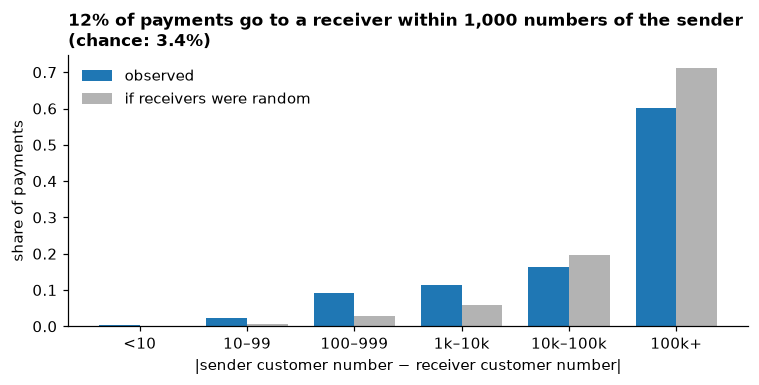

In [8]:
fig, ax = plt.subplots(figsize=(7,3.6)); x = np.arange(len(prox)); w=.38
ax.bar(x-w/2, prox.observed, w, label='observed'); ax.bar(x+w/2, prox.if_random, w, label='if receivers were random', color='0.7')
ax.set_xticks(x); ax.set_xticklabels(prox.distance); ax.set_xlabel('|sender customer number − receiver customer number|'); ax.set_ylabel('share of payments'); ax.legend(frameon=False)
near = prox.observed[:3].sum(); near0 = prox.if_random[:3].sum()
ax.set_title(f'{near:.0%} of payments go to a receiver within 1,000 numbers of the sender\n(chance: {near0:.1%})'); savefig('E1_entity_proximity')

## B. Anomalies
### H-B1  Scam receivers are strangers: they sit outside the sender's neighbourhood

In [9]:
an = d.assign(near=d.dist<1000).groupby('ANOMALY').agg(n=('near','size'), share_near=('near','mean'), median_distance=('dist','median')).reset_index()
export(an,'anomaly_proximity'); an

,ANOMALY,n,share_near,median_distance
0,ACCOUNT_REPLACEMENT_SCAM,139,0.000000,269271.0
1,CEO_SCAM,213,0.014085,264099.0
2,CUSTOMER_RECALL,93,0.075269,256443.0
3,DUPLICATE_PAYMENT,201,0.099502,252672.0
4,FAT_FINGER_MISTAKE,613,0.117455,235251.0
5,NONE,3096332,0.120149,246556.0
6,ROMANCE_SCAM,277,0.064982,306185.0


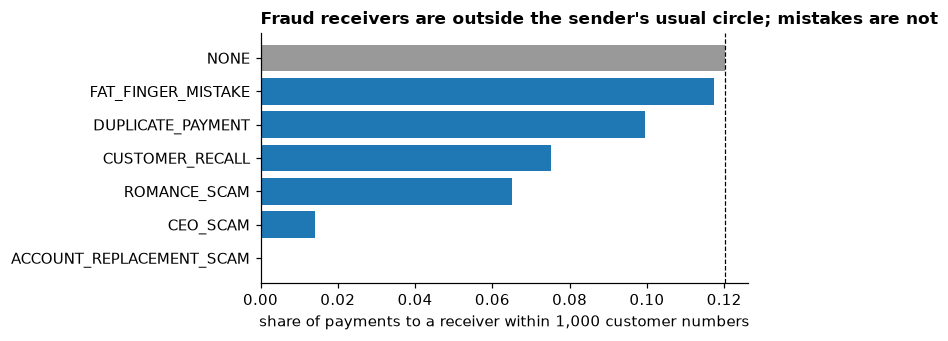

In [10]:
o = an.set_index('ANOMALY').share_near.sort_values(); fig, ax = plt.subplots(figsize=(7,3.2))
ax.barh(o.index, o.values, color=['C0' if i!='NONE' else '0.6' for i in o.index]); ax.axvline(o['NONE'], color='k', lw=.8, ls='--')
ax.set_xlabel('share of payments to a receiver within 1,000 customer numbers'); ax.set_title('Fraud receivers are outside the sender\'s usual circle; mistakes are not'); savefig('E2_anomaly_proximity')

### H-B2  Account replacement: the name on the payment belongs to a party the sender already pays, but the account is new
Test: for each scam payment compare the words of its beneficiary details (account line removed) with those of the sender's normal payments; take the best overlap (Jaccard). Baseline: the same for a random sample of normal payments, excluding payments to the same customer number.

In [11]:
import re
def words(s):
    body = ' '.join(s.split('\n')[1:]) if s.lstrip().startswith('/') else s.replace('\n',' ')
    return frozenset(w for w in re.findall(r'[A-Z]{3,}', body.upper()))
def best_overlap(target_rows):
    senders = tuple(target_rows.ORDERING_ACCOUNT.unique()); con.register('snd', pd.DataFrame({'a': senders}))
    hist = q('''SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, any_value(BENEFICIARY_DETAILS) det FROM p
                WHERE ANOMALY_TYPE IS NULL AND ORDERING_ACCOUNT IN (SELECT a FROM snd) GROUP BY 1,2''')
    hist['w'] = hist.det.map(words); by = dict(tuple(hist.groupby('ORDERING_ACCOUNT')))
    out = []
    for r in target_rows.itertuples():
        h = by.get(r.ORDERING_ACCOUNT)
        if h is None: out.append(np.nan); continue
        h = h[h.BENEFICIARY_ACCOUNT.str[-6:] != r.BENEFICIARY_ACCOUNT[-6:]].head(3000)
        w = words(r.BENEFICIARY_DETAILS)
        out.append(max((len(w & x)/max(len(w | x),1) for x in h.w), default=np.nan))
    return pd.Series(out, index=target_rows.index)
scam = q("SELECT ROW_ID, ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, BENEFICIARY_DETAILS FROM p WHERE ANOMALY_TYPE='ACCOUNT_REPLACEMENT_SCAM'")
ceo  = q("SELECT ROW_ID, ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, BENEFICIARY_DETAILS FROM p WHERE ANOMALY_TYPE='CEO_SCAM'")
norm = q("SELECT ROW_ID, ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, BENEFICIARY_DETAILS FROM p WHERE ANOMALY_TYPE IS NULL AND ORDERING_TYPE='B' USING SAMPLE 700 ROWS (reservoir, 1)")
sc_o, ce_o, no_o = best_overlap(scam), best_overlap(ceo), best_overlap(norm)
nm = pd.DataFrame({'group': ['ACCOUNT_REPLACEMENT_SCAM','CEO_SCAM','normal (sample)'], 'n': [sc_o.notna().sum(), ce_o.notna().sum(), no_o.notna().sum()],
                   'median_best_overlap': [sc_o.median(), ce_o.median(), no_o.median()], 'share_overlap_ge_0.6': [(sc_o>=.6).mean(), (ce_o>=.6).mean(), (no_o>=.6).mean()]})
export(nm,'anomaly_name_match'); nm

,group,n,median_best_overlap,share_overlap_ge_0.6
0,ACCOUNT_REPLACEMENT_SCAM,639,0.090909,0.004622
1,CEO_SCAM,916,0.000000,0.004233
2,normal (sample),545,0.142857,0.168498


**Result: rejected.** Account-replacement payments overlap *less* with the sender's known payees than normal payments do (0.5% vs 18% reach an overlap of 0.6). In this dataset the scam receiver is a stranger with its own name, not a known supplier's name on a new account. Together with H-B1, the reconstructable signature is: business or consumer sender, usual amount, receiver never paid before and outside the sender's neighbourhood, receiver bank often slow.

### H-B3  CEO scam vs account replacement: only the CEO scam inflates the amount

,ANOMALY,count,mean,std,min,25%,50%,75%,max
0,ACCOUNT_REPLACEMENT_SCAM,624.0,0.015094,0.958551,-3.305576,-0.633000,0.035865,0.652274,2.703582
1,CEO_SCAM,818.0,0.692082,1.530047,-4.815977,-0.323887,0.514698,1.578639,4.451371
2,NONE,4768.0,0.038081,0.951970,-3.424923,-0.620657,0.019696,0.686497,3.726263


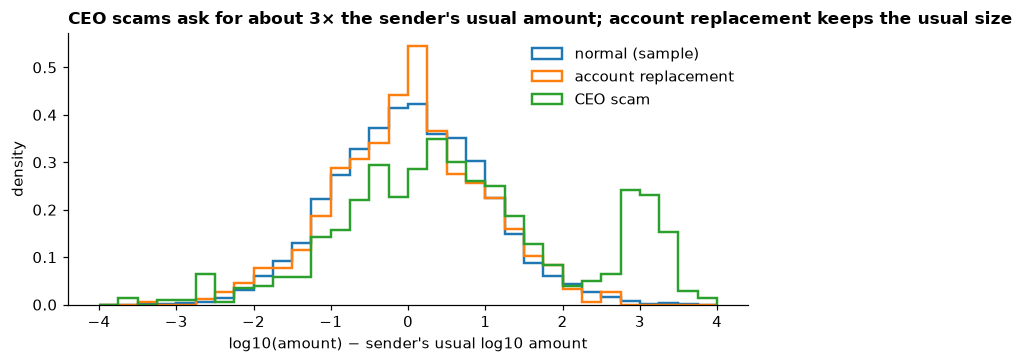

In [12]:
sh = q('''WITH u AS (SELECT ORDERING_ACCOUNT, median(LOG10_USD) m FROM f WHERE NOT IS_ANOMALY GROUP BY 1 HAVING count(*)>=10)
          SELECT a.ANOMALY, a.LOG10_USD - u.m AS shift FROM f a JOIN u USING (ORDERING_ACCOUNT)
          WHERE a.ANOMALY IN ('CEO_SCAM','ACCOUNT_REPLACEMENT_SCAM') OR (a.ANOMALY='NONE' AND a.ROW_ID % 2000 = 0)''')
fig, ax = plt.subplots(figsize=(7,3.4)); b = np.arange(-4,4.01,.25)
for name, lab in [('NONE','normal (sample)'),('ACCOUNT_REPLACEMENT_SCAM','account replacement'),('CEO_SCAM','CEO scam')]:
    ax.hist(sh[sh.ANOMALY==name]['shift'], bins=b, density=True, histtype='step', lw=1.6, label=lab)
ax.set_xlabel("log10(amount) − sender's usual log10 amount"); ax.set_ylabel('density'); ax.legend(frameon=False)
ax.set_title('CEO scams ask for about 3× the sender\'s usual amount; account replacement keeps the usual size'); savefig('E3_scam_amount_vs_usual')
export(sh.groupby('ANOMALY')['shift'].describe().reset_index(),'anomaly_amount_vs_sender_usual')

### H-B4  Duplicates: copies follow the original within two hours

count     516.000000
mean     2824.711240
std      1831.572769
min        12.000000
25%      1251.500000
50%      2677.000000
75%      4240.250000
max      7043.000000
Name: since_first_s, dtype: float64


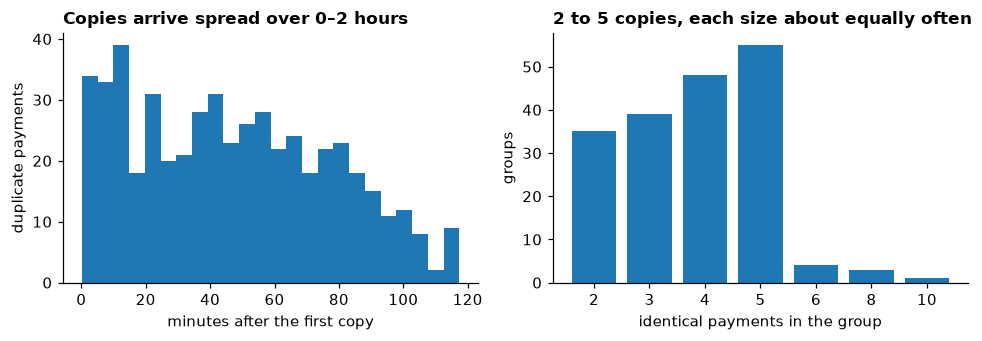

In [13]:
dp = q('''SELECT EPOCH_SECONDS - min(EPOCH_SECONDS) OVER (PARTITION BY ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, USD_AMOUNT) AS since_first_s,
                 count(*) OVER (PARTITION BY ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, USD_AMOUNT) AS copies FROM f WHERE ANOMALY='DUPLICATE_PAYMENT' ''')
later = dp[dp.since_first_s>0]; fig, axes = plt.subplots(1,2, figsize=(9,3.2))
axes[0].hist(later.since_first_s/60, bins=24); axes[0].set_xlabel('minutes after the first copy'); axes[0].set_ylabel('duplicate payments'); axes[0].set_title('Copies arrive spread over 0–2 hours')
c = dp.drop_duplicates().groupby('copies').size(); g = q("SELECT c copies, count(*) n_groups FROM (SELECT count(*) c FROM f WHERE ANOMALY='DUPLICATE_PAYMENT' GROUP BY ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, USD_AMOUNT) GROUP BY 1 ORDER BY 1")
axes[1].bar(g.copies.astype(str), g.n_groups); axes[1].set_xlabel('identical payments in the group'); axes[1].set_ylabel('groups'); axes[1].set_title('2 to 5 copies, each size about equally often')
savefig('E4_duplicates'); export(g,'anomaly_duplicate_group_sizes'); print(later.since_first_s.describe())

### H-B5  CUSTOMER_RECALL (label not described in the case study): can anything in the row distinguish it from a normal payment?

In [14]:
rc = q('''SELECT ANOMALY, count(*) n, median(USD_AMOUNT) median_usd, avg(LOG10_USD) mean_log10, avg((ORDERING_TYPE='B')::int) sender_B, avg((BENEFICIARY_TYPE='B')::int) receiver_B,
                 avg(IS_DOMESTIC::int) domestic, avg(PARTICIPANT_COUNT) participants, avg((TRANSACTION_TYPE_CODE='Covered')::int) covered,
                 median(TOTAL_DURATION) median_duration, avg(IS_WEEKEND::int) weekend, avg(HAS_GAP::int) gap, avg(CURRENCY_CONVERSION_COUNT) fx
          FROM f WHERE ANOMALY IN ('NONE','CUSTOMER_RECALL') GROUP BY 1'''); export(rc,'anomaly_customer_recall_vs_normal'); rc.T

,0,1
ANOMALY,NONE,CUSTOMER_RECALL
n,10392378,332
median_usd,3662.31,3164.25
mean_log10,3.543323,3.543631
sender_B,0.787561,0.777108
receiver_B,0.288199,0.259036
domestic,0.071091,0.054217
participants,2.581674,2.638554
covered,0.041623,0.045181
median_duration,56.0,54.5


In [15]:
q('''SELECT count(*) recalls,
            sum((EXISTS (SELECT 1 FROM f o WHERE o.ORDERING_ACCOUNT=a.ORDERING_ACCOUNT AND o.BENEFICIARY_ACCOUNT=a.BENEFICIARY_ACCOUNT AND o.USD_AMOUNT=a.USD_AMOUNT AND o.ROW_ID<>a.ROW_ID))::int) AS with_same_amount_twin,
            sum((EXISTS (SELECT 1 FROM f o WHERE o.ORDERING_ACCOUNT=a.BENEFICIARY_ACCOUNT AND o.BENEFICIARY_ACCOUNT=a.ORDERING_ACCOUNT))::int) AS with_reverse_payment
     FROM f a WHERE a.ANOMALY='CUSTOMER_RECALL' ''')

,recalls,with_same_amount_twin,with_reverse_payment
0,332,0.0,18.0


**Negative result.** On every column we can observe, recalled payments look like normal ones, and they have no twin or return payment. We conclude the label is assigned at random to about 32 payments per million, and say so rather than invent a rule.

### Dashboard overview charts

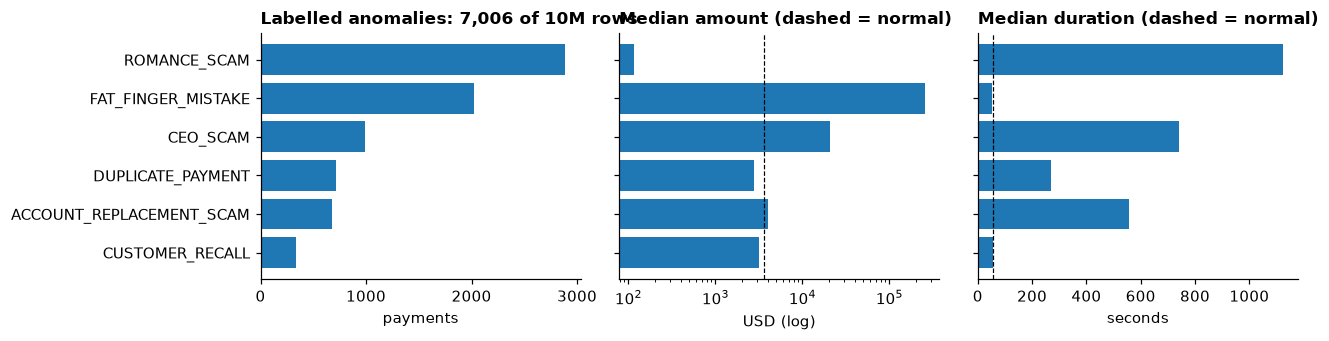

In [16]:
ov = q('''SELECT ANOMALY, count(*) n, median(USD_AMOUNT) median_usd, median(TOTAL_DURATION) median_duration FROM f GROUP BY 1''').set_index('ANOMALY')
a = ov.drop('NONE').sort_values('n'); fig, axes = plt.subplots(1,3, figsize=(12,3.2))
axes[0].barh(a.index, a.n); axes[0].set_title('Labelled anomalies: 7,006 of 10M rows'); axes[0].set_xlabel('payments')
axes[1].barh(a.index, a.median_usd); axes[1].axvline(ov.median_usd['NONE'], color='k', ls='--', lw=.8); axes[1].set_xscale('log'); axes[1].set_title('Median amount (dashed = normal)'); axes[1].set_xlabel('USD (log)'); axes[1].set_yticklabels([])
axes[2].barh(a.index, a.median_duration); axes[2].axvline(ov.median_duration['NONE'], color='k', ls='--', lw=.8); axes[2].set_title('Median duration (dashed = normal)'); axes[2].set_xlabel('seconds'); axes[2].set_yticklabels([])
savefig('E5_anomaly_overview')

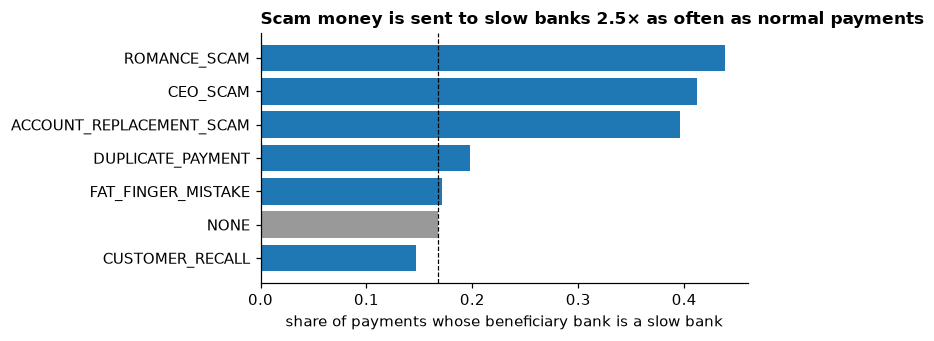

In [17]:
sb = pd.read_csv('../outputs/csv/anomaly_bank_speed.csv').set_index('ANOMALY').beneficiary_bank_slow.sort_values()
fig, ax = plt.subplots(figsize=(7,3.2)); ax.barh(sb.index, sb.values, color=['C0' if i!='NONE' else '0.6' for i in sb.index]); ax.axvline(sb['NONE'], color='k', ls='--', lw=.8)
ax.set_xlabel('share of payments whose beneficiary bank is a slow bank'); ax.set_title('Scam money is sent to slow banks 2.5× as often as normal payments'); savefig('E6_anomaly_slow_banks')

## C. Path endpoints that differ from the BIC columns
### H-C1  In 5% of payments each end of the path is replaced by a random bank; the BIC columns keep the customer's real bank

In [18]:
ep = q('''SELECT avg((NOT PATH_FIRST_IS_ORD)::int) first_differs, avg((NOT PATH_LAST_IS_BEN)::int) last_differs,
                 avg((NOT PATH_FIRST_IS_ORD AND NOT PATH_LAST_IS_BEN)::int) both_differ FROM f'''); ep['both_if_independent'] = ep.first_differs*ep.last_differs; export(ep,'endpoint_mismatch'); ep

,first_differs,last_differs,both_differ,both_if_independent
0,0.049828,0.049928,0.002464,0.002488


In [19]:
pd.concat([
  rule_check('mismatch rows: IBAN country still = ORDERING_BIC8 country', 'ORD_ACC_COUNTRY = ORD_COUNTRY', 'NOT PATH_FIRST_IS_ORD AND ORD_ACC_IS_IBAN'),
  rule_check('mismatch rows: IBAN bank code still = ORDERING_BIC8 prefix', 'substr(ORDERING_ACCOUNT,11,4)=substr(ORDERING_BIC8,1,4)', 'NOT PATH_FIRST_IS_ORD AND ORD_ACC_IS_IBAN'),
  rule_check('mismatch rows: path start in the same country as ORDERING_BIC8', "substr(string_split(BIC8_PATH,';')[1],5,2)=ORD_COUNTRY", 'NOT PATH_FIRST_IS_ORD'),
])

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,mismatch rows: IBAN country still = ORDERING_B...,281751,281751.0,100.0000,0.0
0,mismatch rows: IBAN bank code still = ORDERING...,281751,281751.0,100.0000,0.0
0,mismatch rows: path start in the same country ...,518207,25026.0,4.8293,493181.0


In [20]:
q('''SELECT PATH_FIRST_IS_ORD AND PATH_LAST_IS_BEN AS endpoints_match, count(*) n, avg(LOG10_USD) mean_log_amount, median(TOTAL_DURATION) median_duration,
            avg(PARTICIPANT_COUNT) participants, avg(HAS_GAP::int) gap, 1e4*avg(IS_ANOMALY::int) anomalies_per_10k FROM f GROUP BY 1''')

,endpoints_match,n,mean_log_amount,median_duration,participants,gap,anomalies_per_10k
0,False,1011829,3.543590,56.0,2.58196,0.076303,3.804991
1,True,9388171,3.543221,56.0,2.58164,0.076765,7.708637


## D. Weekend effect in local time
Notebook 02 measured weekdays in UTC, which blends time zones. Here each country's clock is shifted so that its activity centre falls at 13:00 (assumption: every country has the same daily shape, shown in notebook 02), and the weekday is recomputed.

In [21]:
tz = pd.read_csv('../outputs/csv/time_country_centre_hour.csv')[['ORD_COUNTRY','centre_hour_utc']]
allc = q('''SELECT ORD_COUNTRY, HOUR_UTC, count(*) n FROM f WHERE NOT IS_WEEKEND GROUP BY ALL''')
ang = 2*np.pi*allc.HOUR_UTC/24; cm = allc.assign(s=allc.n*np.sin(ang), c=allc.n*np.cos(ang)).groupby('ORD_COUNTRY')[['s','c','n']].sum()
cm['shift_h'] = np.round(((np.arctan2(cm.s, cm.c)*24/(2*np.pi)) % 24) - 13).astype(int); cm.loc[cm.n<5000,'shift_h'] = 0
con.register('tzs', cm[['shift_h']].reset_index())
lw = q('''SELECT isodow(TS_UTC - to_seconds(3600*shift_h)) AS local_dow, ORDERING_TYPE, count(*) n,
                 count(DISTINCT CAST(TS_UTC - to_seconds(3600*shift_h) AS DATE)) n_days FROM f JOIN tzs USING (ORD_COUNTRY) GROUP BY ALL ORDER BY 2,1''')
lw['per_day'] = lw.n/lw.n_days; pv = lw.pivot(index='local_dow', columns='ORDERING_TYPE', values='per_day'); pv = pv/pv.iloc[:5].mean()
utc = pd.read_csv('../outputs/csv/time_day_of_week.csv').set_index('DOW')[['B_vs_weekday','C_vs_weekday']]
cmp = pd.DataFrame({'UTC_business': utc.B_vs_weekday, 'local_business': pv.B, 'UTC_consumer': utc.C_vs_weekday, 'local_consumer': pv.C}); export(cmp.reset_index(),'time_weekend_local_vs_utc'); cmp.round(3)

,UTC_business,local_business,UTC_consumer,local_consumer
1,0.974,0.993,0.970,0.991
2,0.976,0.963,0.976,0.964
3,0.974,0.964,0.974,0.963
4,1.029,1.020,1.028,1.020
5,1.047,1.060,1.051,1.061
6,0.248,0.208,0.252,0.212
7,0.363,0.349,0.363,0.350


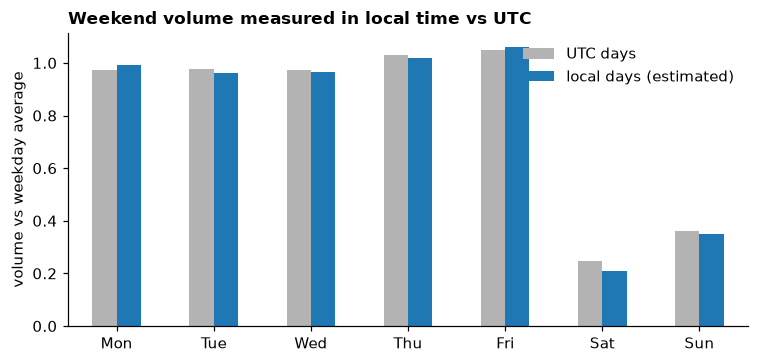

In [22]:
fig, ax = plt.subplots(figsize=(7,3.4)); cmp[['UTC_business','local_business']].plot.bar(ax=ax, color=['0.7','C0'])
ax.set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], rotation=0); ax.set_ylabel('volume vs weekday average'); ax.set_xlabel(''); ax.legend(['UTC days','local days (estimated)'], frameon=False)
ax.set_title('Weekend volume measured in local time vs UTC'); savefig('E7_weekend_local_vs_utc')

## E. Dashboard charts for earlier rules

,link,n,share_converting,country_pairs
0,same country,450274.0,0.0,24
1,"different country, same currency area",484233.0,0.0,153
2,different currency area,4424223.0,1.0,1494


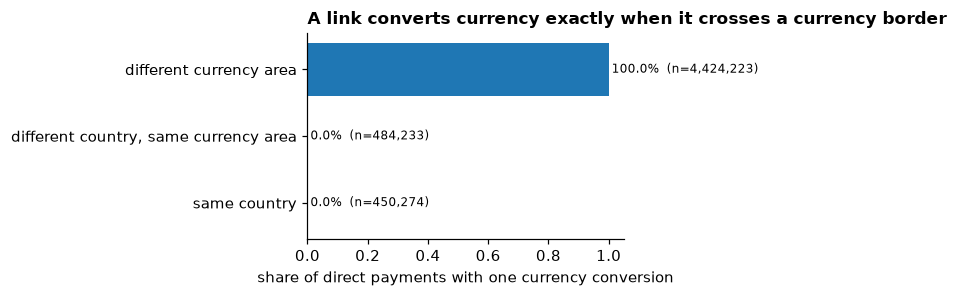

In [23]:
fx = pd.read_csv('../outputs/csv/fx_direct_border.csv'); 
z = q('''WITH d AS (SELECT substr(string_split(BIC8_PATH,';')[1],5,2) c1, substr(string_split(BIC8_PATH,';')[2],5,2) c2, CURRENCY_CONVERSION_COUNT fx FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP),
              pr AS (SELECT c1, c2, avg(fx) p, count(*) n FROM d GROUP BY 1,2)
         SELECT CASE WHEN c1=c2 THEN 'same country' WHEN p<0.02 THEN 'different country, same currency area' ELSE 'different currency area' END AS link, sum(n) n, sum(p*n)/sum(n) AS share_converting, count(*) country_pairs
         FROM pr WHERE n>=500 GROUP BY 1 ORDER BY 3'''); export(z,'fx_rule_summary')
fig, ax = plt.subplots(figsize=(7,2.8)); ax.barh(z.link, z.share_converting); ax.set_xlim(0,1.05); ax.set_xlabel('share of direct payments with one currency conversion')
for i,(v,n) in enumerate(zip(z.share_converting, z.n)): ax.text(v+.01, i, f'{v:.1%}  (n={n:,.0f})', va='center', fontsize=8)
ax.set_title('A link converts currency exactly when it crosses a currency border'); savefig('E8_fx_rule'); z

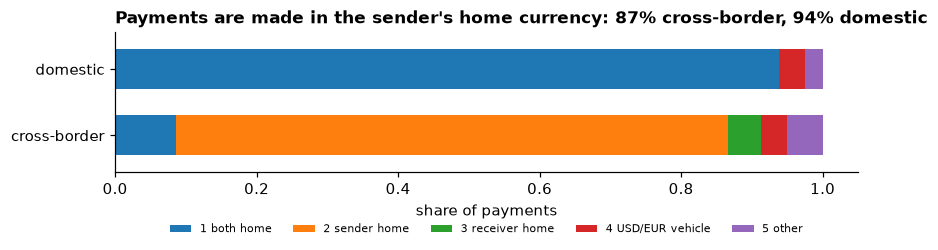

In [24]:
cc = pd.read_csv('../outputs/csv/currency_choice_rule.csv'); pv = cc.pivot(index='IS_DOMESTIC', columns='currency_choice', values='share').fillna(0)
pv.index = ['cross-border','domestic']; fig, ax = plt.subplots(figsize=(8,2.6)); pv.plot.barh(stacked=True, ax=ax, width=.6)
ax.set_xlabel('share of payments'); ax.legend(fontsize=7, frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(.5,-.3)); ax.set_title('Payments are made in the sender\'s home currency: 87% cross-border, 94% domestic'); savefig('E9_currency_choice')

,k,IS_DOMESTIC,n,share_covered
0,3,False,2245815,0.106535
1,4,False,826559,0.106507
2,5,False,303213,0.106414
3,6,False,111783,0.105982
4,7,False,41199,0.106774
5,3,True,171690,0.200023
6,4,True,62944,0.197811
7,5,True,23516,0.203266
8,6,True,8603,0.204347
9,7,True,3192,0.192356


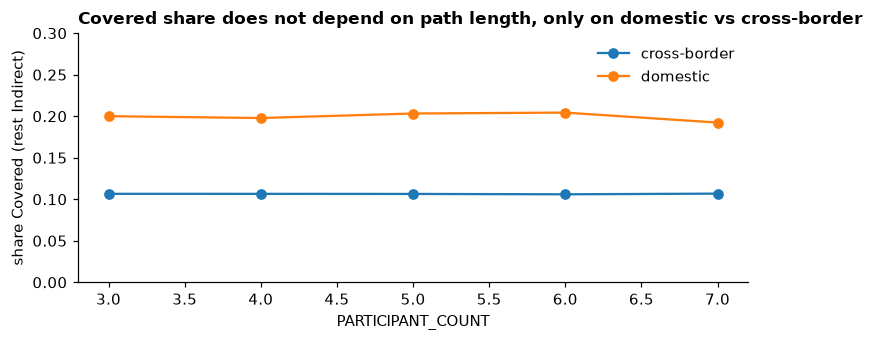

In [25]:
cv = q('''SELECT PARTICIPANT_COUNT k, IS_DOMESTIC, count(*) n, avg((TRANSACTION_TYPE_CODE='Covered')::int) share_covered FROM f WHERE PARTICIPANT_COUNT BETWEEN 3 AND 7 GROUP BY ALL ORDER BY 2,1''')
export(cv,'routing_covered_by_k_domestic'); fig, ax = plt.subplots(figsize=(7,3.2))
for dom, g in cv.groupby('IS_DOMESTIC'): ax.plot(g.k, g.share_covered, 'o-', label='domestic' if dom else 'cross-border')
ax.set_ylim(0,.3); ax.set_xlabel('PARTICIPANT_COUNT'); ax.set_ylabel('share Covered (rest Indirect)'); ax.legend(frameon=False)
ax.set_title('Covered share does not depend on path length, only on domestic vs cross-border'); savefig('E10_covered_share'); cv

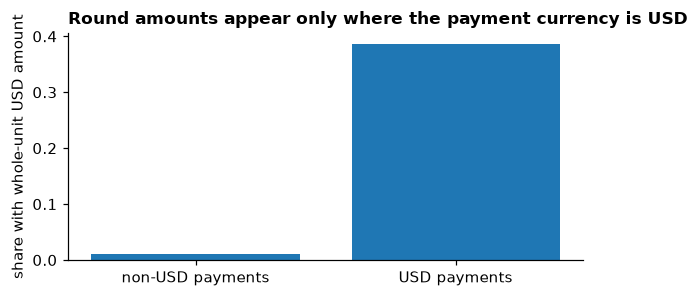

In [26]:
rn = pd.read_csv('../outputs/csv/amount_roundness.csv'); fig, ax = plt.subplots(figsize=(5.5,2.8))
ax.bar(['non-USD payments','USD payments'], rn.sort_values('is_usd').share_whole_units); ax.set_ylabel('share with whole-unit USD amount')
ax.set_title('Round amounts appear only where the payment currency is USD'); savefig('E11_round_amounts')

,top_share_of_accounts,share_of_payments
0,0.001,0.181052
1,0.010,0.458523
2,0.100,0.827210
3,0.500,0.972921


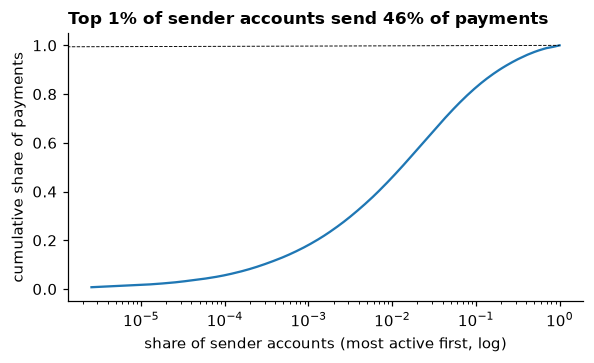

In [27]:
sn = q('SELECT count(*) n FROM f GROUP BY ORDERING_ACCOUNT ORDER BY n DESC'); cum = sn.n.cumsum()/sn.n.sum(); x = np.arange(1,len(sn)+1)/len(sn)
fig, ax = plt.subplots(figsize=(5.5,3.4)); ax.plot(x, cum); ax.plot([0,1],[0,1],'k--',lw=.6); ax.set_xscale('log'); ax.set_xlabel('share of sender accounts (most active first, log)'); ax.set_ylabel('cumulative share of payments')
ax.set_title(f'Top 1% of sender accounts send {cum.iloc[len(sn)//100]:.0%} of payments'); savefig('E12_sender_concentration')
export(pd.DataFrame({'top_share_of_accounts':[.001,.01,.1,.5], 'share_of_payments':[cum.iloc[int(len(sn)*s)] for s in [.001,.01,.1,.5]]}),'party_sender_concentration')

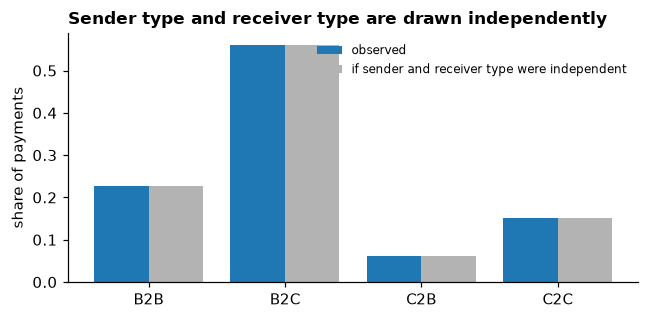

In [28]:
fl = pd.read_csv('../outputs/csv/party_flow_mix.csv'); fl['flow'] = fl.o+'2'+fl.b; x = np.arange(4); fig, ax = plt.subplots(figsize=(6,3))
ax.bar(x-.2, fl.share, .4, label='observed'); ax.bar(x+.2, fl.expected_if_independent, .4, label='if sender and receiver type were independent', color='0.7')
ax.set_xticks(x); ax.set_xticklabels(fl.flow); ax.set_ylabel('share of payments'); ax.legend(frameon=False, fontsize=8); ax.set_title('Sender type and receiver type are drawn independently'); savefig('E13_flow_mix')

,tok,share_of_B,share_of_C
0,chr,0.859867,0.879178
1,street,0.694696,0.702640
2,city,0.647396,0.687188
3,country_code,0.605491,0.619599
4,iban,0.497540,0.532241
5,line_break,0.463609,0.469506
6,post_code,0.426053,0.457587
7,last_name,0.000000,0.861837
8,business,0.853876,0.000000
9,other_words,0.319335,0.331315


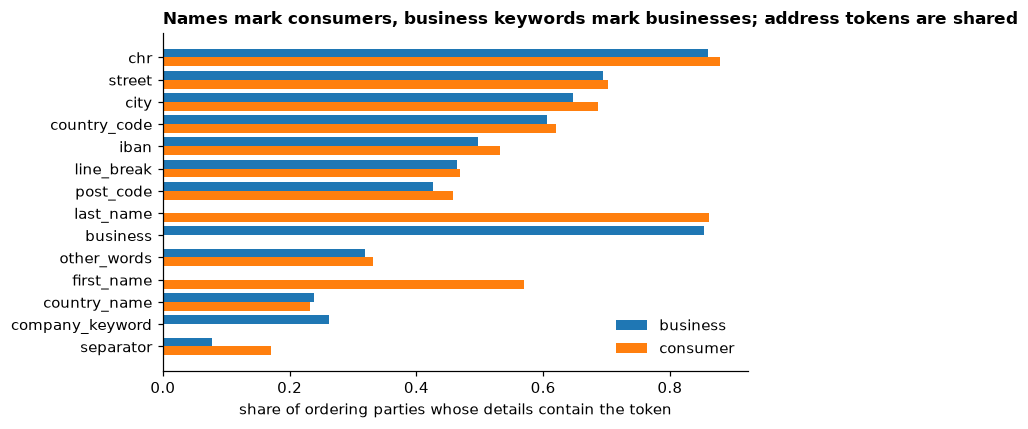

In [29]:
tk = q('''SELECT tok, sum((ty='B')::int) n_B, sum((ty='C')::int) n_C
          FROM (SELECT unnest(list_distinct(regexp_extract_all(ORDERING_TOKENS,'<([a-z_]+)',1))) tok, ORDERING_TYPE ty FROM p WHERE ROW_ID % 20 = 0) GROUP BY 1''')
tot = q("SELECT sum((ORDERING_TYPE='B')::int) b, sum((ORDERING_TYPE='C')::int) c FROM p WHERE ROW_ID % 20 = 0").iloc[0]
tk['share_of_B'] = tk.n_B/tot.b; tk['share_of_C'] = tk.n_C/tot.c
tk = tk.assign(t=tk.share_of_B+tk.share_of_C).sort_values('t', ascending=False).head(14).drop(columns=['t','n_B','n_C']).reset_index(drop=True); export(tk,'party_token_types')
fig, ax = plt.subplots(figsize=(7,4)); y = np.arange(len(tk))[::-1]; ax.barh(y+.2, tk.share_of_B, .4, label='business'); ax.barh(y-.2, tk.share_of_C, .4, label='consumer')
ax.set_yticks(y); ax.set_yticklabels(tk.tok); ax.set_xlabel('share of ordering parties whose details contain the token'); ax.legend(frameon=False)
ax.set_title('Names mark consumers, business keywords mark businesses; address tokens are shared'); savefig('E14_token_types'); tk